# Seguro Empresarial — auditoria, variáveis e regressão ordinal

Notebook executado em 28/10/2026. Categorias: ESSENCIAL, PRATICO e TOTAL. Plano de referência por estabelecimento ainda ausente. Os resultados abaixo separam auditoria de dados, hipóteses de variáveis e modelagem supervisionada. A proposta IPU foi descartada.

In [1]:
from pathlib import Path
import sys, json, subprocess
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT/'src'))
OUT=ROOT/'resultados'
print('Projeto:',ROOT)
print('Python:',sys.version.split()[0],'pandas:',pd.__version__)

Projeto: /home/lucas/Documentos/hackathon/seguro_empresarial
Python: 3.12.14 pandas: 3.1.0


## 1. Reproduzir preparação e conferir as fontes
Uma linha por estabelecimento; sem rateio de receita/funcionários e sem rótulos inventados. Os arquivos originais são preservados.

In [2]:
r=subprocess.run([sys.executable,str(ROOT/'src/preparar_base.py'),'--origem',str(ROOT/'dados/originais'),'--saida',str(ROOT/'dados/preparados')],capture_output=True,text=True,check=True)
print(r.stdout)
from analisar import executar as auditar
display(auditar())
from gerar_entrega import auditoria_fontes
fontes=auditoria_fontes()
display(fontes[['arquivo','igual_ao_original']])

desenvolvimento {'linhas': 2978, 'empresas': 2500, 'colunas': 25, 'rotulos_plano_preenchidos': 0, 'area_ausente': 1838}
correlações para revisão: [{'variavel_1': 'faturamento_mensal_empresa', 'variavel_2': 'funcionarios_estimados_empresa', 'pearson': 0.935232}]
teste_comum {'linhas': 144, 'empresas': 120, 'colunas': 25, 'rotulos_plano_preenchidos': 0, 'area_ausente': 87}
correlações para revisão: [{'variavel_1': 'faturamento_mensal_empresa', 'variavel_2': 'funcionarios_estimados_empresa', 'pearson': 0.941555}]



{'variaveis_examinadas': 62,
 'cenarios_demonstrados': 23,
 'treino_linhas': 2390,
 'avaliacao_linhas': 588,
 'empresas_sobrepostas': 0,
 'modelo_treinado': False,
 'motivo': 'Ausência de plano de referência por estabelecimento',
 'limites_score_estimados': False,
 'melhor_modelo_identificado': False}

,arquivo,igual_ao_original
0,Seguro_Empresarial_Desenvolvimento/bens_cadast...,True
1,Seguro_Empresarial_Desenvolvimento/catalogo_co...,True
2,Seguro_Empresarial_Desenvolvimento/dicionario_...,True
3,Seguro_Empresarial_Desenvolvimento/empresas.csv,True
4,Seguro_Empresarial_Desenvolvimento/enderecos_e...,True
5,Seguro_Empresarial_Desenvolvimento/sinais_fina...,True
6,Seguro_Empresarial_Desenvolvimento/template_co...,True
7,Seguro_Empresarial_Desenvolvimento/template_re...,True
8,Seguro_Empresarial_Desenvolvimento/territorio.csv,True
9,Seguro_Empresarial_Teste_Comum/bens_cadastrado...,True


## 2. Situação por plano e possibilidade de treinamento
Conhecer o nome das classes é diferente de ter exemplos associados às classes. Não é obrigatório conhecer o plano contratado para treinar recomendação: pode-se usar um plano de referência revisado.

In [3]:
display(pd.read_csv(OUT/'situacao_por_plano.csv'))
from treinar import executar as modelar
estado=modelar()
display(estado)

,plano,coberturas_catalogadas,exemplos_rotulados,acuracia,situacao
0,ESSENCIAL,5,0,NÃO ESTIMÁVEL,Categoria conhecida; vínculo cliente-plano aus...
1,PRATICO,7,0,NÃO ESTIMÁVEL,Categoria conhecida; vínculo cliente-plano aus...
2,TOTAL,9,0,NÃO ESTIMÁVEL,Categoria conhecida; vínculo cliente-plano aus...


{'treinado': False,
 'motivo': 'As três categorias existem, mas nenhum estabelecimento está associado a um plano de referência.',
 'n_rotulos': 0,
 'n_categorias_previstas': 3,
 'acuracia': None,
 'coeficientes': None,
 'limites_score': None}

## 3. Testes contra os dados originais
A aprovação dos testes demonstra integridade da preparação e funcionamento das barreiras de entrada. Não mede acerto de recomendação de planos.

In [4]:
r=subprocess.run([sys.executable,str(ROOT/'tests/test_integridade.py')],capture_output=True,text=True)
print(r.stdout)
if r.returncode: print(r.stderr); print((OUT/'testes_execucao.txt').read_text()); raise RuntimeError('Falha nos testes')
display(pd.read_csv(OUT/'testes_integridade.csv').fillna(''))

Testes: 26; falhas: 0; erros: 0



/tmp/ipykernel_68068/2822245671.py:4: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(pd.read_csv(OUT/'testes_integridade.csv').fillna(''))


,teste,resultado,detalhe
0,test_01_contagens_desenvolvimento,APROVADO,
1,test_02_contagens_comum,APROVADO,
2,test_03_chaves_sem_duplicacao,APROVADO,
3,test_04_faturamento_sem_rateio,APROVADO,
4,test_05_funcionarios_sem_rateio,APROVADO,
5,test_06_quantidade_unidades,APROVADO,
6,test_07_estoque_por_estabelecimento,APROVADO,
7,test_08_soma_bens_por_estabelecimento,APROVADO,
8,test_09_contagem_bens,APROVADO,
9,test_10_area_indisponivel,APROVADO,


## 4. Inspecionar outras variáveis
Tabela ampliada de diagnóstico, não lista de preditores finais. Inclui aliases para conferência. Ausência considera códigos como NAO_DISPONIVEL e área zero. Nenhuma associação estatística com plano foi estimada.

In [5]:
display(pd.read_csv(OUT/'resumo_bases.csv'))
qualidade=pd.read_csv(OUT/'qualidade_todas_variaveis.csv')
print('Campos examinados:',len(qualidade))
with pd.option_context('display.max_rows',100): display(qualidade)

,base,estabelecimentos,empresas,planos_referencia,area_ausente_pct,corr_receita_funcionarios_por_estabelecimento,corr_receita_funcionarios_por_empresa,corr_estoque_medio_pico,unidades_multiempresa
0,desenvolvimento,2978,2500,0,61.719275,0.935232,0.934565,0.994683,956
1,teste_comum,144,120,0,60.416667,0.941555,0.945752,0.992516,48


Campos examinados: 62


,variavel,tipo,distintos,ausentes_ou_indisponiveis,pct_indisponivel,pct_zeros,mediana,p95,observacao
0,grupo_atividade,categorica,10,0,0.000,NaN,NaN,NaN,Varia na base; utilidade para planos ainda não...
1,faturamento_mensal_empresa,numerica,2232,0,0.000,0.000,1.917500e+05,1.163592e+06,Varia na base; utilidade para planos ainda não...
2,funcionarios_estimados_empresa,numerica,66,0,0.000,0.000,6.000000e+00,3.900000e+01,Varia na base; utilidade para planos ainda não...
3,quantidade_estabelecimentos_empresa,numerica,2,0,0.000,0.000,1.000000e+00,2.000000e+00,Varia na base; utilidade para planos ainda não...
4,tipo_unidade,categorica,2,0,0.000,NaN,NaN,NaN,Varia na base; utilidade para planos ainda não...
5,area_m2,numerica,144,1838,61.719,0.000,4.000000e+02,7.150000e+02,Varia na base; utilidade para planos ainda não...
6,estoque_medio_estimado,numerica,1641,0,0.000,0.000,2.570000e+04,4.166350e+05,Varia na base; utilidade para planos ainda não...
7,valor_bens_ponderado_estabelecimento,numerica,2538,0,0.000,0.000,1.315750e+05,1.065585e+06,Varia na base; utilidade para planos ainda não...
8,possui_termo_loja,numerica,2,0,0.000,76.226,0.000000e+00,1.000000e+00,Varia na base; utilidade para planos ainda não...
9,possui_termo_galeria,numerica,2,0,0.000,87.408,0.000000e+00,1.000000e+00,Varia na base; utilidade para planos ainda não...


## 5. Redundância e estabilidade potencial dos coeficientes
Correlação não seleciona sozinha o modelo. O VIF abaixo usa apenas variáveis numéricas em log e 1.140 casos completos; não substitui o diagnóstico da especificação final com categorias.

,variavel_a,variavel_b,pearson,iguais_em_todas_as_linhas
0,faturamento_mensal_empresa,faturamento_mensal,1.000000,True
1,funcionarios_estimados_empresa,quantidade_funcionarios_estimada,1.000000,True
2,area_m2,area_cadastrada_m2,1.000000,False
3,dependencia_digital_pct,indice_maturidade_digital,1.000000,True
4,estoque_medio_estimado,estoque_pico_estimado,0.994683,False
5,valor_bens_ponderado_estabelecimento,valor_bens_bruto,0.981999,False
6,folha_pagamento_mensal,despesa_fixa_mensal_estimada,0.958430,False
7,percentual_vendas_online_estimado,indice_dependencia_plataformas,0.958185,False
8,percentual_receita_delivery_est,probabilidade_delivery_referencia,0.956468,False
9,percentual_recebimentos_digitais,indice_receita_digital,0.937720,False


,variavel,vif_log_casos_completos,n
0,faturamento_mensal_empresa,13.554416,1140
1,funcionarios_estimados_empresa,10.902736,1140
2,area_m2,1.000275,1140
3,estoque_medio_estimado,1.760599,1140
4,valor_bens_ponderado_estabelecimento,2.724009,1140


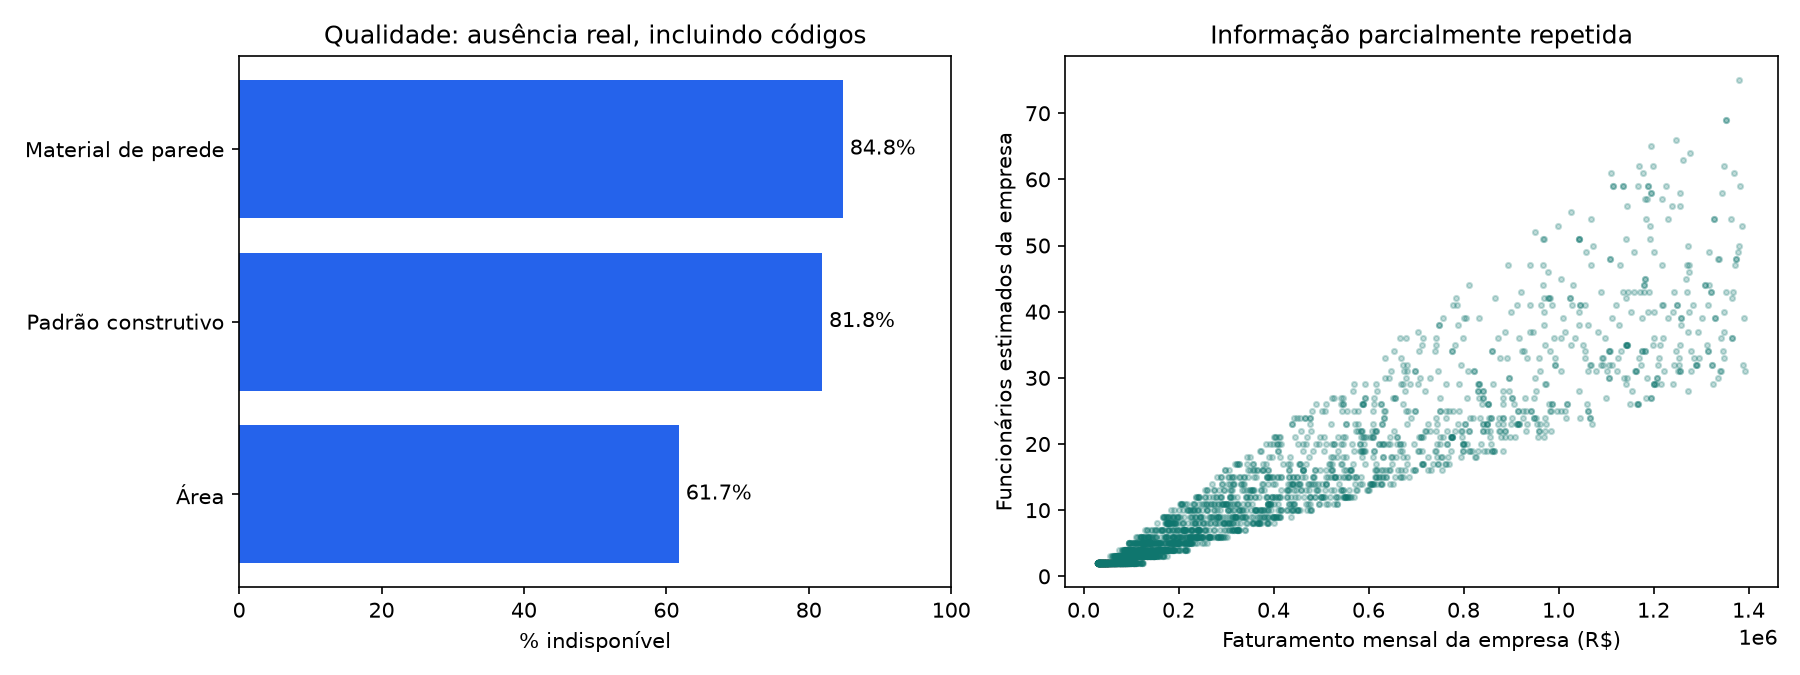

In [6]:
display(pd.read_csv(OUT/'redundancias.csv').head(30))
display(pd.read_csv(OUT/'vif_exploratorio.csv'))
display(Image(filename=str(OUT/'diagnostico_variaveis.png')))

## 6. Decisão sobre cada candidata
Revisamos a lista inicial. A primeira especificação tem atividade, funcionários, número de unidades, tipo de unidade, estoque e bens. A alternativa econômica substitui funcionários por faturamento; uma terceira avalia área. Nenhuma foi declarada superior em previsão.

In [7]:
display(pd.read_csv(OUT/'decisoes_variaveis.csv'))
from treinar import ESPECIFICACOES
display(ESPECIFICACOES)

,variavel,decisao,evidencia_ou_hipotese,limite,significancia_para_planos
0,grupo_atividade,MANTER PARA TESTAR,Representa atividades com diferentes necessida...,Categorias não possuem ordem numérica,NÃO AVALIÁVEL SEM ASSOCIAÇÕES DE REFERÊNCIA
1,funcionarios_estimados_empresa,MANTER PARA TESTAR,Hipótese relacionada à operação e RC empregado...,"É da empresa inteira, não funcionários locais",NÃO AVALIÁVEL SEM ASSOCIAÇÕES DE REFERÊNCIA
2,quantidade_estabelecimentos_empresa,CONTROLE DE CONTEXTO,Permite contextualizar medidas corporativas re...,"Contagem do pacote, não critério automático de...",NÃO AVALIÁVEL SEM ASSOCIAÇÕES DE REFERÊNCIA
3,tipo_unidade,CONTROLE DE CONTEXTO,Matriz/filial; dado completo,Contribuição adicional só poderá ser medida com Y,NÃO AVALIÁVEL SEM ASSOCIAÇÕES DE REFERÊNCIA
4,estoque_medio_estimado,MANTER PARA TESTAR,Estoque do estabelecimento; dado completo e co...,Já é estimativa; não mede risco de roubo,NÃO AVALIÁVEL SEM ASSOCIAÇÕES DE REFERÊNCIA
5,valor_bens_ponderado_estabelecimento,MANTER PARA TESTAR,Agregação confere integralmente com valores po...,Não é importância segurada nem comprovação de ...,NÃO AVALIÁVEL SEM ASSOCIAÇÕES DE REFERÊNCIA
6,faturamento_mensal_empresa,ALTERNATIVA À VARIÁVEL FUNCIONÁRIOS,"Correlação por empresa 0,9346; VIF exploratóri...",Não descartar definitivamente; comparar modelo...,NÃO AVALIÁVEL SEM ASSOCIAÇÕES DE REFERÊNCIA
7,area_m2,MODELO ALTERNATIVO,"61,72% ausente; avaliar modelo com e sem área",Imputador deve ser ajustado só no treino; ausê...,NÃO AVALIÁVEL SEM ASSOCIAÇÕES DE REFERÊNCIA
8,estoque_pico_estimado,ALTERNATIVA AO ESTOQUE MÉDIO,"Correlação 0,9947, sem identidade de valores","Usar como alternativa, não os dois automaticam...",NÃO AVALIÁVEL SEM ASSOCIAÇÕES DE REFERÊNCIA
9,indice_maturidade_digital,EXCLUIR DUPLICATA,Idêntica a dependencia_digital_pct nos 2.500 r...,"A exclusão é por duplicação, não por significâ...",NÃO AVALIÁVEL SEM ASSOCIAÇÕES DE REFERÊNCIA


{'emprego': ['grupo_atividade',
  'quantidade_estabelecimentos_empresa',
  'tipo_unidade',
  'estoque_medio_estimado',
  'valor_bens_ponderado_estabelecimento',
  'funcionarios_estimados_empresa'],
 'economia': ['grupo_atividade',
  'quantidade_estabelecimentos_empresa',
  'tipo_unidade',
  'estoque_medio_estimado',
  'valor_bens_ponderado_estabelecimento',
  'faturamento_mensal_empresa'],
 'emprego_area': ['grupo_atividade',
  'quantidade_estabelecimentos_empresa',
  'tipo_unidade',
  'estoque_medio_estimado',
  'valor_bens_ponderado_estabelecimento',
  'funcionarios_estimados_empresa',
  'area_m2']}

## 7. Resultados explícitos de cada cenário
Pelo menos um exemplo de cada atividade e condição relevante de cadastro. Estes não são exemplos validados de cada plano. Valores monetários em reais; funcionários e receita mantêm a granularidade da empresa.

In [8]:
casos=pd.read_csv(OUT/'casos_demonstracao.csv')
print('Cenários cobertos:',len(casos))
with pd.option_context('display.max_rows',100,'display.max_columns',30): display(casos)
display(pd.read_csv(OUT/'perfil_por_atividade.csv'))

Cenários cobertos: 23


,empresa_id,imovel_id,grupo_atividade,tipo_unidade,faturamento_mensal_empresa,funcionarios_estimados_empresa,quantidade_estabelecimentos_empresa,area_m2,area_ausente,estoque_medio_estimado,valor_bens_ponderado_estabelecimento,origem_faturamento,proporcao_bens_baixa_confianca,situacao_imovel_cadastral,endereco_cnpj_compativel,caso,casos_disponiveis,plano_de_referencia,resultado
0,EMP_00027,IMO_EMP_00027_01,BELEZA,MATRIZ,120450,6,1,NaN,1,62100,92100,INFORMADO,0.500000,EM_OBRA,SIM,atividade_BELEZA,297,SEM ROTULO,Conferido com fontes; recomendação de plano pe...
1,EMP_00010,IMO_EMP_00010_01,CLINICA,MATRIZ,190950,4,1,NaN,1,32650,144350,INFORMADO,0.333333,EM_OBRA,SIM,atividade_CLINICA,322,SEM ROTULO,Conferido com fontes; recomendação de plano pe...
2,EMP_00015,IMO_EMP_00015_01,ELETRONICOS,MATRIZ,40600,2,2,NaN,1,3300,53850,INFORMADO,0.000000,REGULAR,SIM,atividade_ELETRONICOS,289,SEM ROTULO,Conferido com fontes; recomendação de plano pe...
3,EMP_00005,IMO_EMP_00005_01,ESCOLA_CURSO,MATRIZ,138700,3,1,355.0,0,72750,95100,PRESUMIDO_COM_BASE_EM_GASTOS,0.000000,REGULAR,SIM,atividade_ESCOLA_CURSO,274,SEM ROTULO,Conferido com fontes; recomendação de plano pe...
4,EMP_00032,IMO_EMP_00032_01,ESCRITORIO,MATRIZ,85500,4,1,NaN,1,2250,17950,PRESUMIDO_COM_BASE_EM_GASTOS,1.000000,REGULAR,NAO,atividade_ESCRITORIO,300,SEM ROTULO,Conferido com fontes; recomendação de plano pe...
5,EMP_00001,IMO_EMP_00001_01,FARMACIA,MATRIZ,388500,11,2,NaN,1,125900,318000,INFORMADO,0.000000,REGULAR,SIM,atividade_FARMACIA,305,SEM ROTULO,Conferido com fontes; recomendação de plano pe...
6,EMP_00002,IMO_EMP_00002_01,MERCADO,MATRIZ,986150,26,2,395.0,0,138950,1525050,PRESUMIDO_COM_BASE_EM_GASTOS,0.500000,REGULAR,NAO,atividade_MERCADO,304,SEM ROTULO,Conferido com fontes; recomendação de plano pe...
7,EMP_00008,IMO_EMP_00008_01,OFICINA,MATRIZ,289850,15,2,175.0,0,15400,237200,INFORMADO,0.000000,REGULAR,SIM,atividade_OFICINA,309,SEM ROTULO,Conferido com fontes; recomendação de plano pe...
8,EMP_00072,IMO_EMP_00072_01,RESTAURANTE,MATRIZ,269000,11,2,NaN,1,131200,77850,INFORMADO,0.333333,REGULAR,SIM,atividade_RESTAURANTE,304,SEM ROTULO,Conferido com fontes; recomendação de plano pe...
9,EMP_00009,IMO_EMP_00009_01,VAREJO_MODA,MATRIZ,36000,2,1,NaN,1,24300,41150,INFORMADO,0.600000,EM_OBRA,SIM,atividade_VAREJO_MODA,274,SEM ROTULO,Conferido com fontes; recomendação de plano pe...


,grupo_atividade,estabelecimentos,faturamento_mediano_empresa,funcionarios_medianos_empresa,estoque_mediano,bens_ponderados_medianos
0,BELEZA,297,168750.0,5.0,16450.0,116100.0
1,CLINICA,322,215050.0,7.0,13925.0,142225.0
2,ELETRONICOS,289,228300.0,8.0,52450.0,140900.0
3,ESCOLA_CURSO,274,175900.0,5.0,10600.0,120950.0
4,ESCRITORIO,300,227625.0,7.0,10125.0,144625.0
5,FARMACIA,305,160350.0,5.0,43900.0,124850.0
6,MERCADO,304,213775.0,6.5,45850.0,156500.0
7,OFICINA,309,229250.0,7.0,32000.0,141250.0
8,RESTAURANTE,304,189575.0,5.0,33875.0,128525.0
9,VAREJO_MODA,274,171625.0,5.0,38250.0,101950.0


## 8. Separação por empresa
A partição é proposta e fixa, sem consultar desempenho ou ajustar regras na avaliação. O Teste Comum é usado para aplicação e preparação, não para escolher variáveis.

In [9]:
part=pd.read_csv(OUT/'particao_empresas_proposta.csv')
display(part.groupby('particao_proposta').agg(linhas=('imovel_id','size'),empresas=('empresa_id','nunique')))
a=set(part[part.particao_proposta.eq('treino_desenvolvimento')].empresa_id)
b=set(part[part.particao_proposta.eq('avaliacao_reservada')].empresa_id)
print('Empresas compartilhadas:',len(a&b))

,linhas,empresas
particao_proposta,,
avaliacao_reservada,588,500
treino_desenvolvimento,2390,2000


Empresas compartilhadas: 0


## 9. Modelagem preparada e limites
`src/treinar.py` prevê comparação ordinal em cinco dobras agrupadas, seleção por log loss e avaliação reservada. O score é uma transformação da posição ordinal e não a probabilidade de comprar. Os limiares vêm do ajuste; a regra de classificação é a mediana das classes. Chances proporcionais e calibração ainda exigirão análise depois dos rótulos. Valores-p após seleção são exploratórios.

Quando não há planos associados aos exemplos, coeficientes, acurácia e cortes devem permanecer ausentes.

In [10]:
if estado.get('treinado'):
    display(pd.read_csv(OUT/'comparacao_modelos_cv.csv'))
    display(pd.read_csv(OUT/'matriz_confusao_avaliacao.csv'))
    display(pd.read_csv(OUT/'coeficientes_exploratorios.csv'))
else:
    print('Acurácia: NÃO ESTIMÁVEL')
    print('Significância em relação aos planos: NÃO ESTIMÁVEL')
    print('Limites do score: AINDA NÃO ESTIMADOS')
    print('Preencher dados/rotulos/rotulos_revisados.csv com referências revisadas.')

Acurácia: NÃO ESTIMÁVEL
Significância em relação aos planos: NÃO ESTIMÁVEL
Limites do score: AINDA NÃO ESTIMADOS
Preencher dados/rotulos/rotulos_revisados.csv com referências revisadas.


## 10. Como defender na apresentação
“Testamos a integridade dos dados, documentamos as hipóteses de variáveis e mostramos casos reais do dataset. Encontramos redundância entre tamanho econômico e funcionários, muitos dados de área ausentes e índices duplicados. Nossa comparação de modelos será por empresas separadas e só poderá medir acerto depois da associação de planos de referência. A solução busca recomendação rastreável e revisão humana, com limites de validade explícitos.”

Referências: [Statsmodels — modelo ordinal](https://www.statsmodels.org/stable/examples/notebooks/generated/ordinal_regression.html), [Scikit-learn — validação agrupada](https://scikit-learn.org/stable/modules/cross_validation.html), [calibração](https://scikit-learn.org/stable/modules/calibration.html).